sp500 1950-01-03 2026-10-09 19315 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
sp500 // DCA: 8,348,699 // SMA50: -0.21% // SMA100: -0.87% // SMA200: -1.37% // average n=2-200: -0.75% // best n: 10 +0.13% // worst n: 182 -1.89% // lengths that beat DCA: 11 of 199
   group means vs DCA: 1-20: +0.00% | 21-40: -0.14% | 41-60: -0.16% | 61-80: -0.58% | 81-100: -0.95% | 101-120: -1.13% | 121-140: -0.91% | 141-160: -0.78% | 161-180: -1.28% | 181-200: -1.49% | 
nasdaq_comp 1971-02-05 2026-10-09 14037 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
nasdaq_comp // DCA: 13,677,404 // SMA50: -0.78% // SMA100: -0.91% // SMA200: -0.57% // average n=2-200: -0.99% // best n: 2 -0.23% // worst n: 67 -1.69% // lengths that beat DCA: 0 of 199
   group means vs DCA: 1-20: -0.36% | 21-40: -0.90% | 41-60: -0.83% | 61-80: -1.37% | 81-100: -0.81% | 101-120: -1.04% | 121-140: -1.28% | 141-160: -1.18% | 161-180: -1.24% | 181-200: -0.88% | 
nasdaq100 1985-10-01 2026-10-09 10336 //

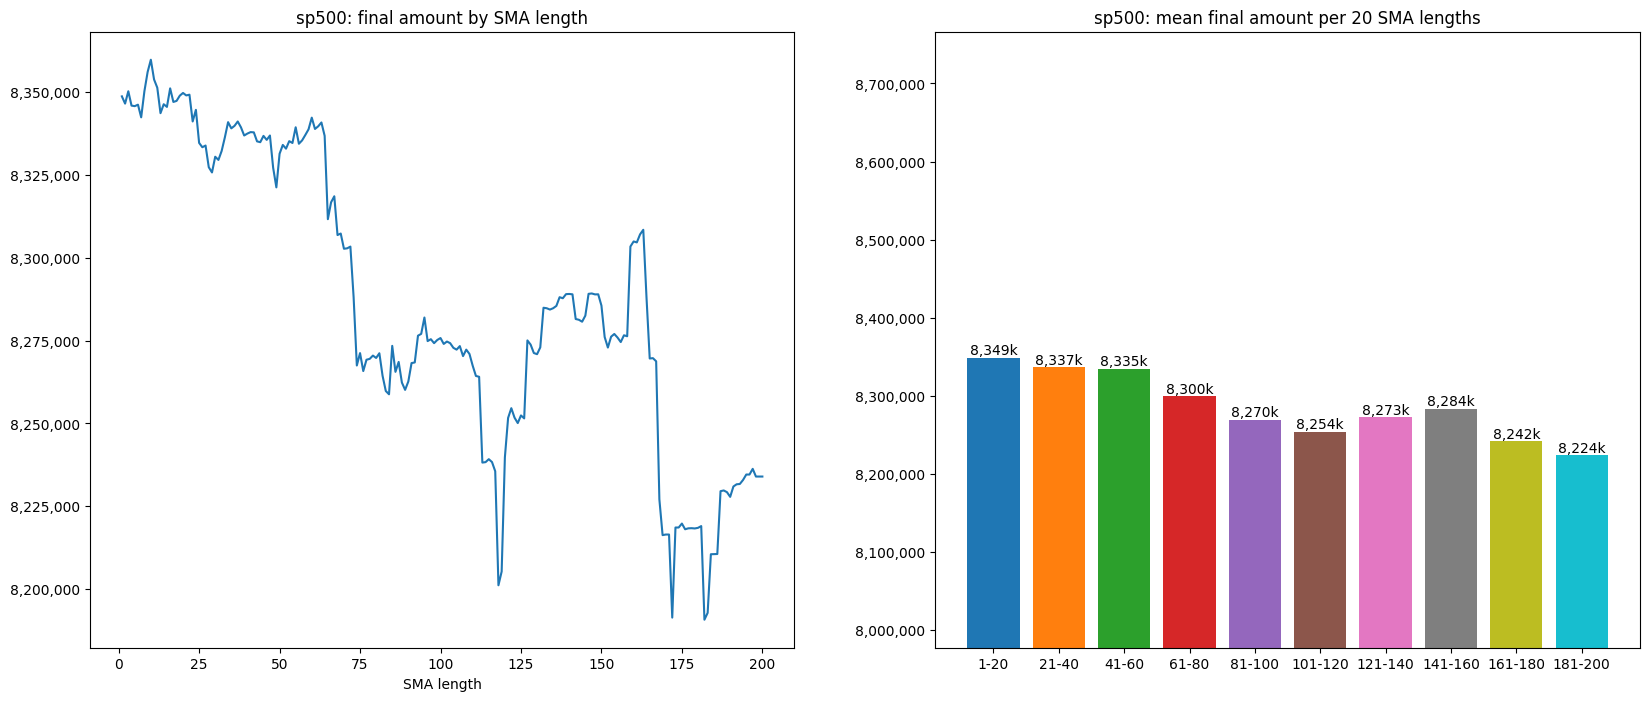

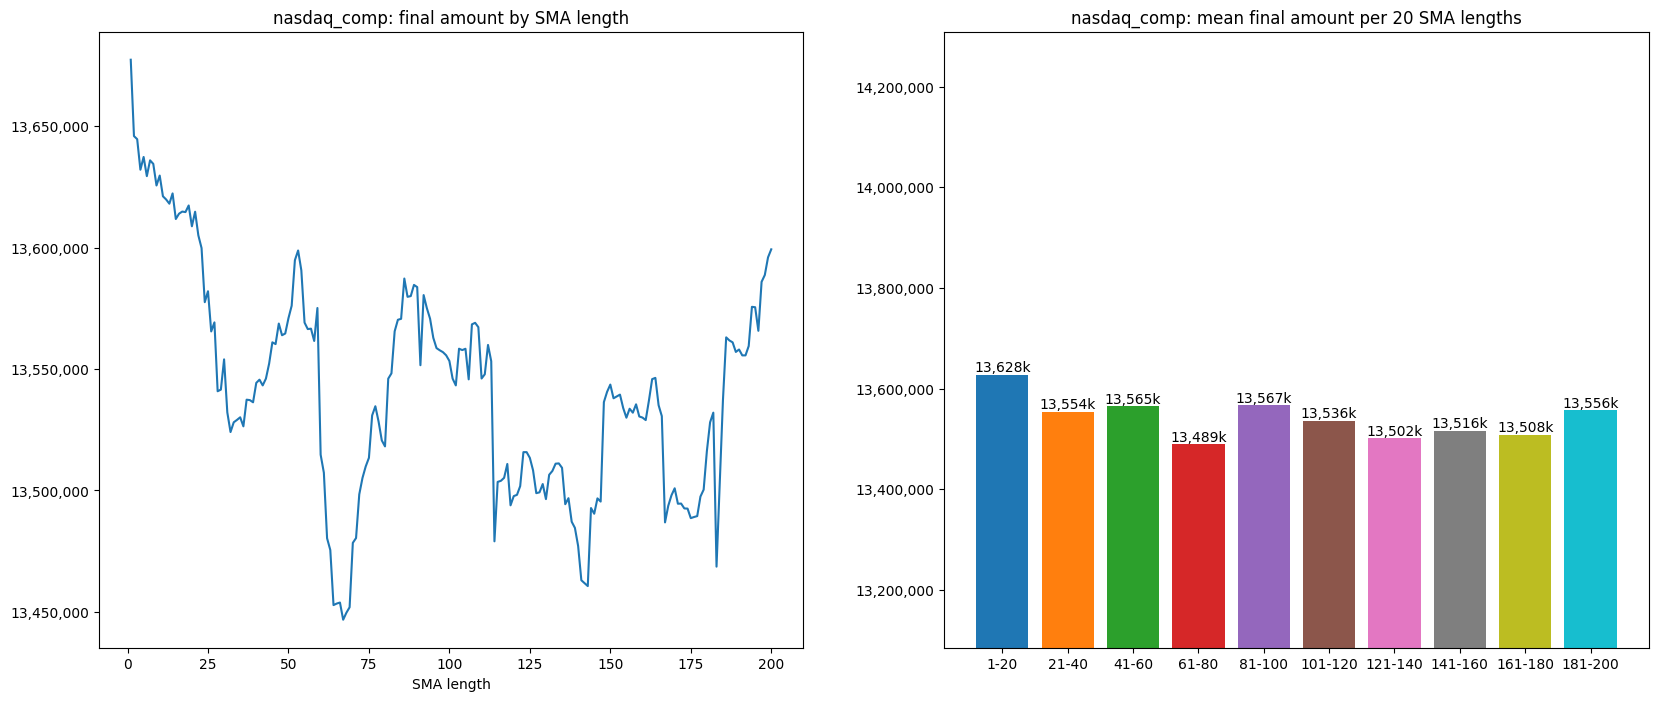

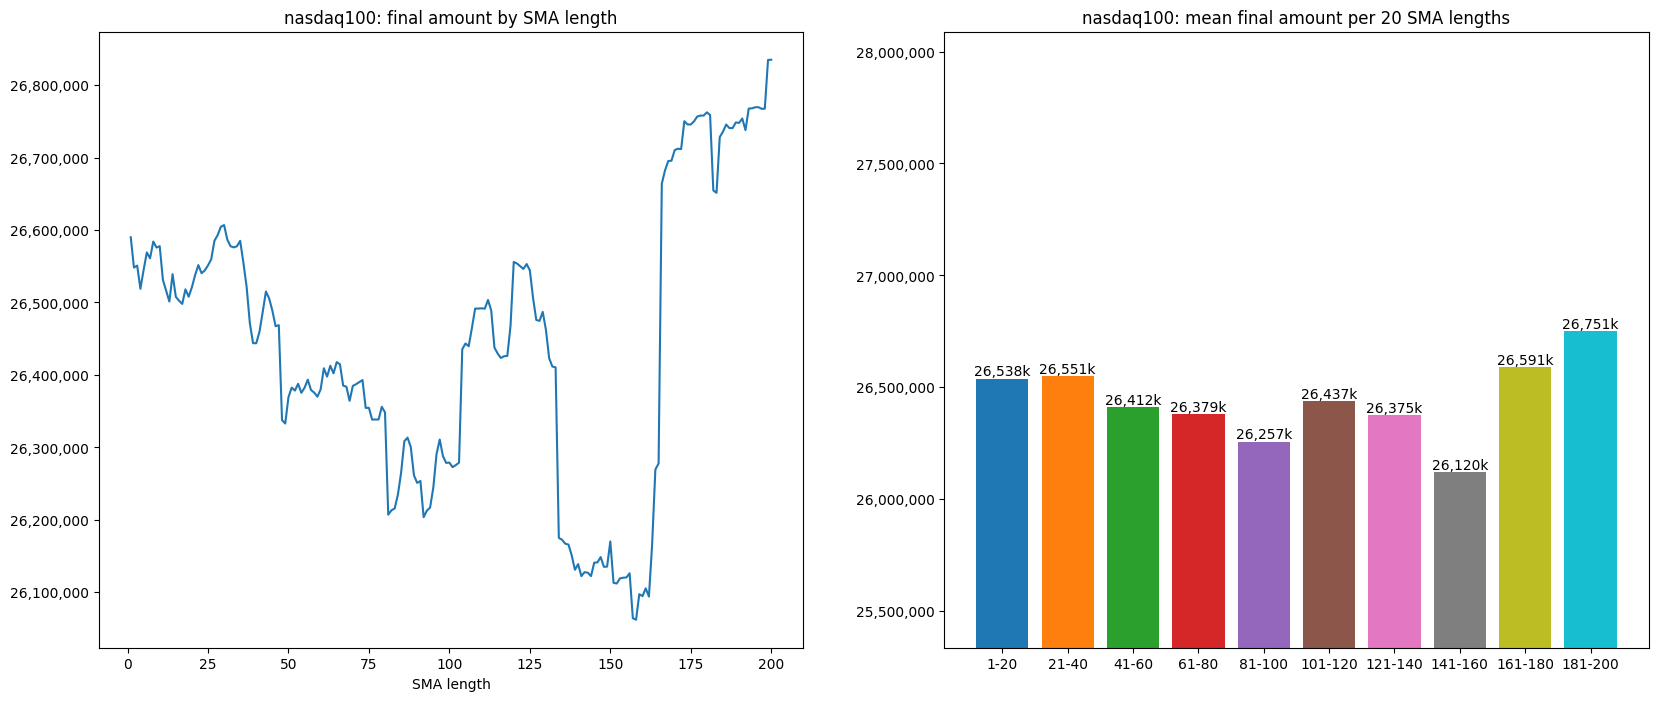

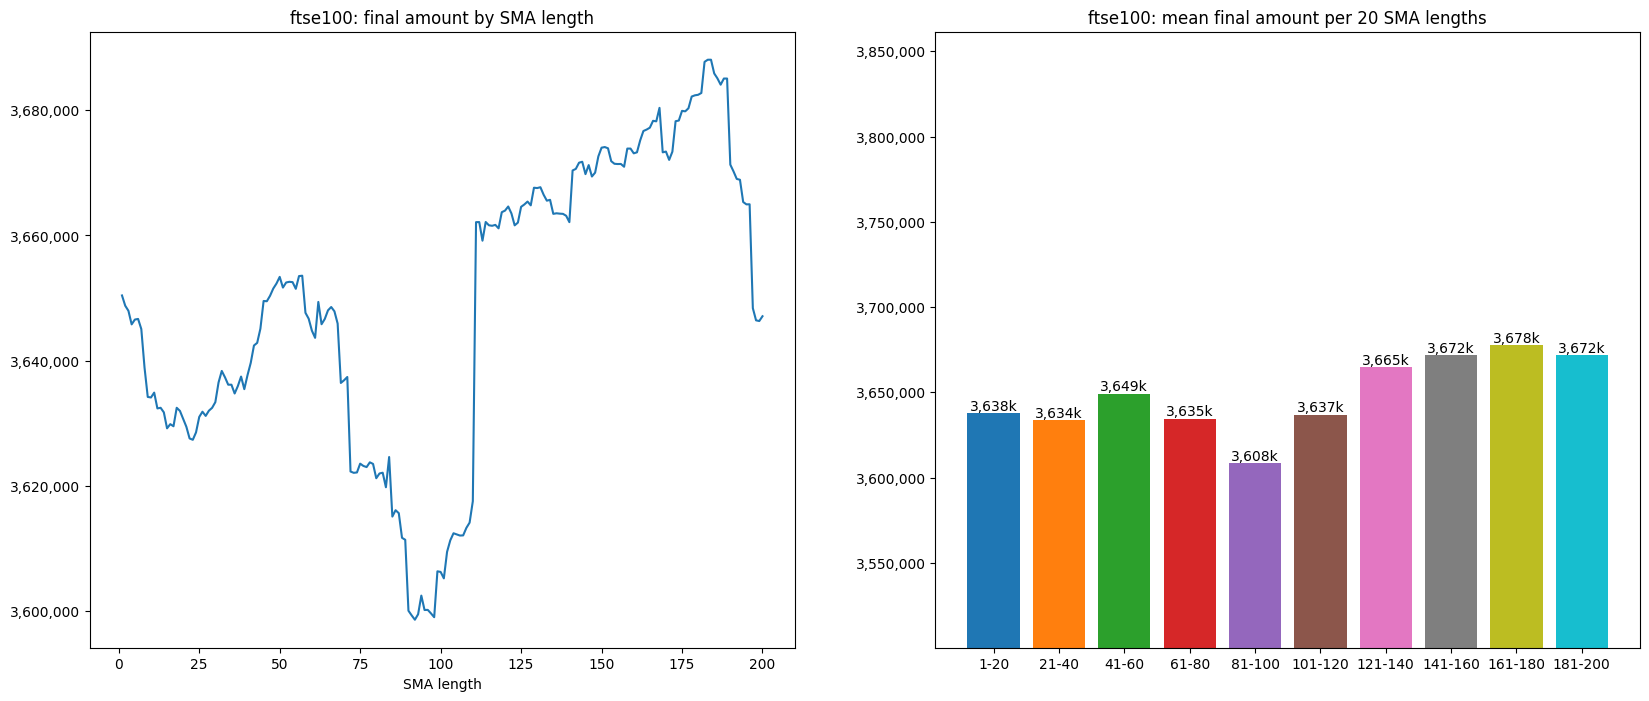

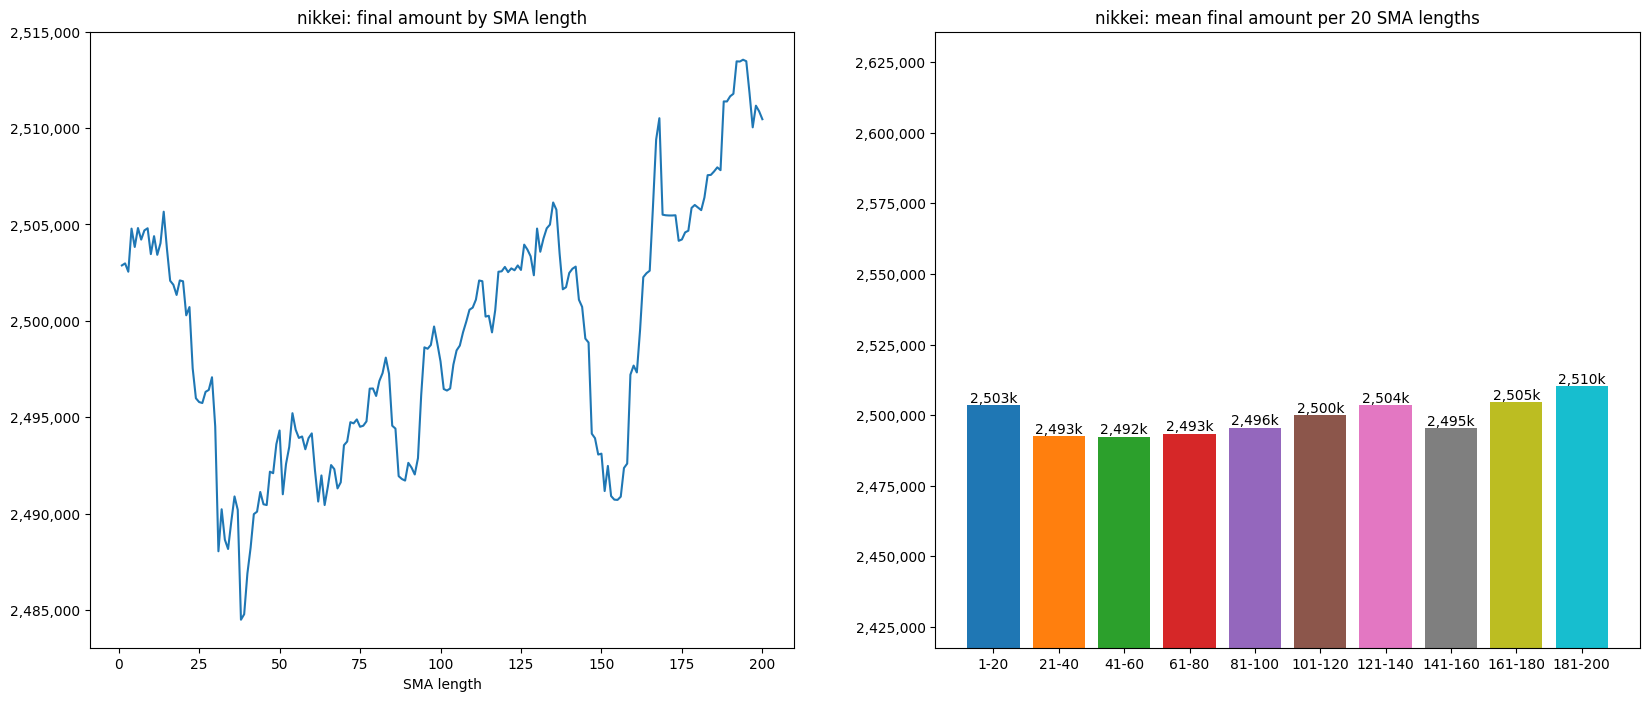

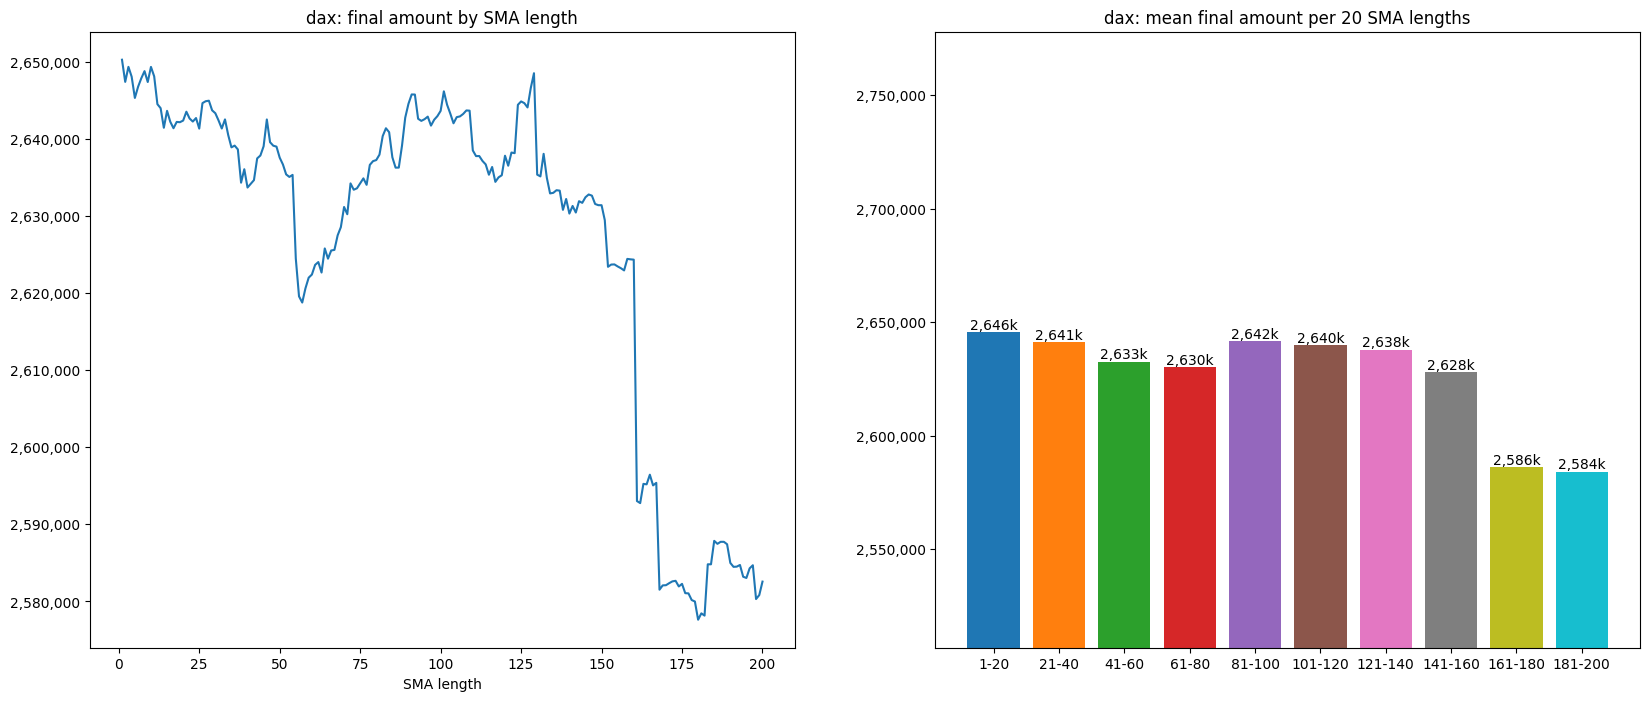

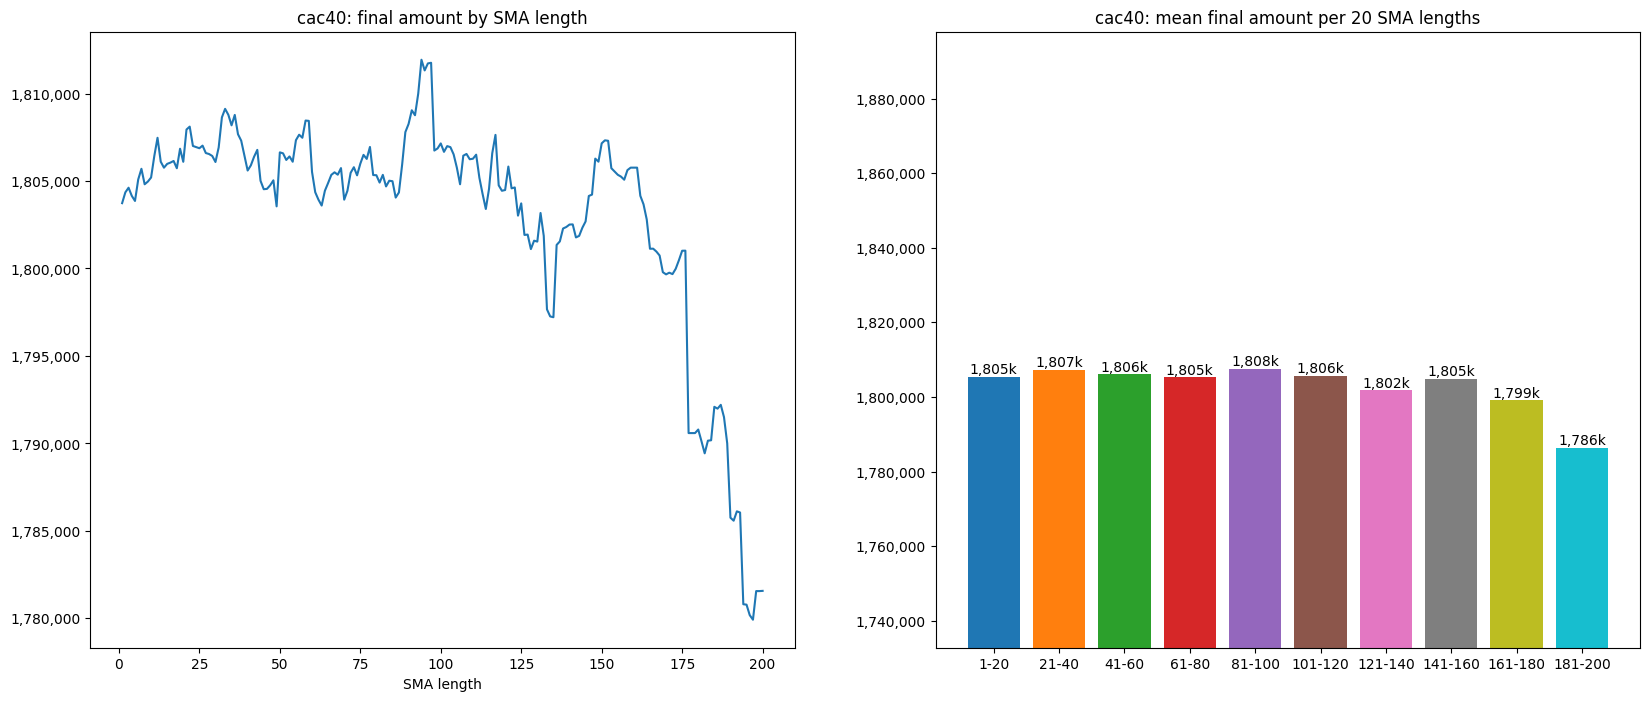

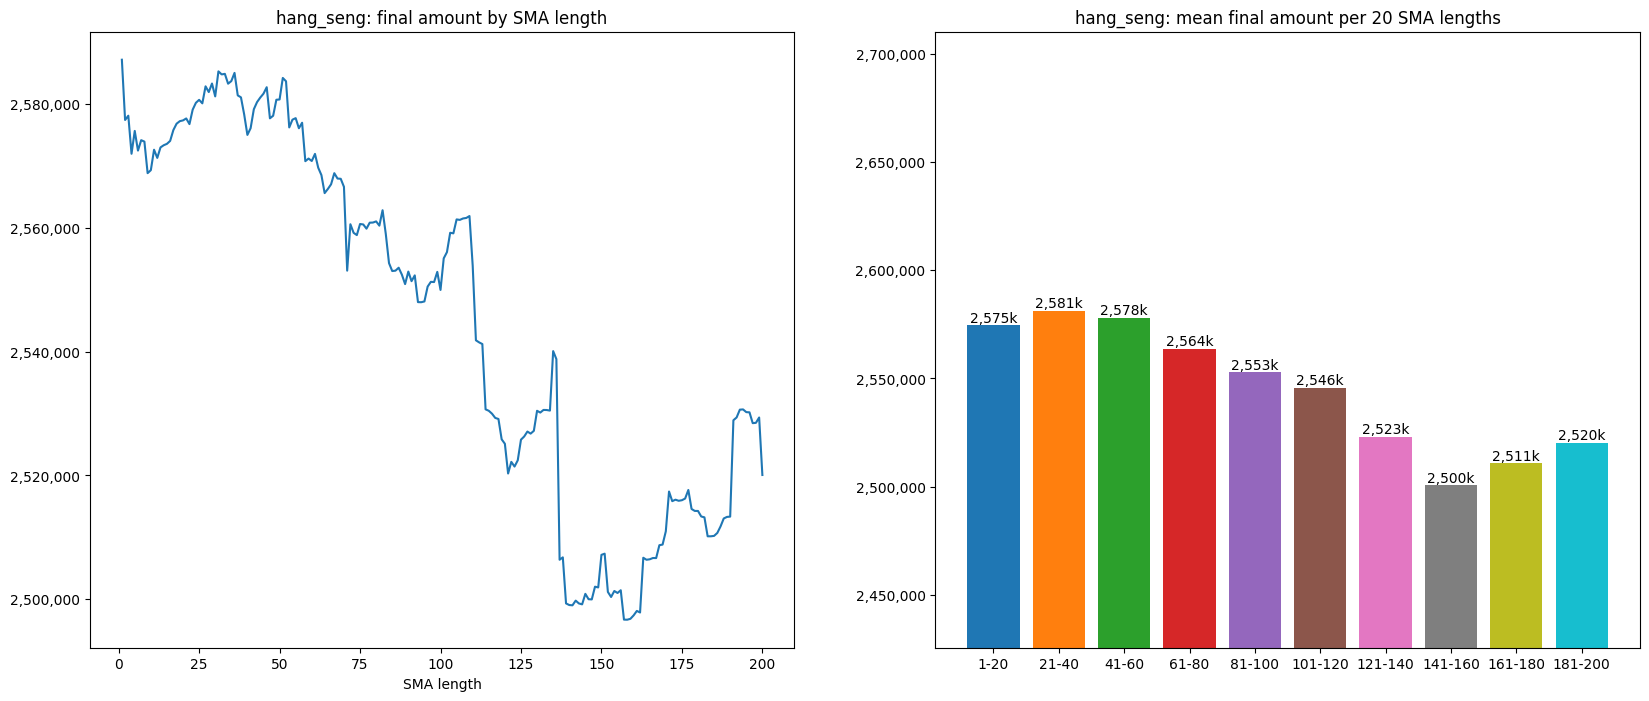

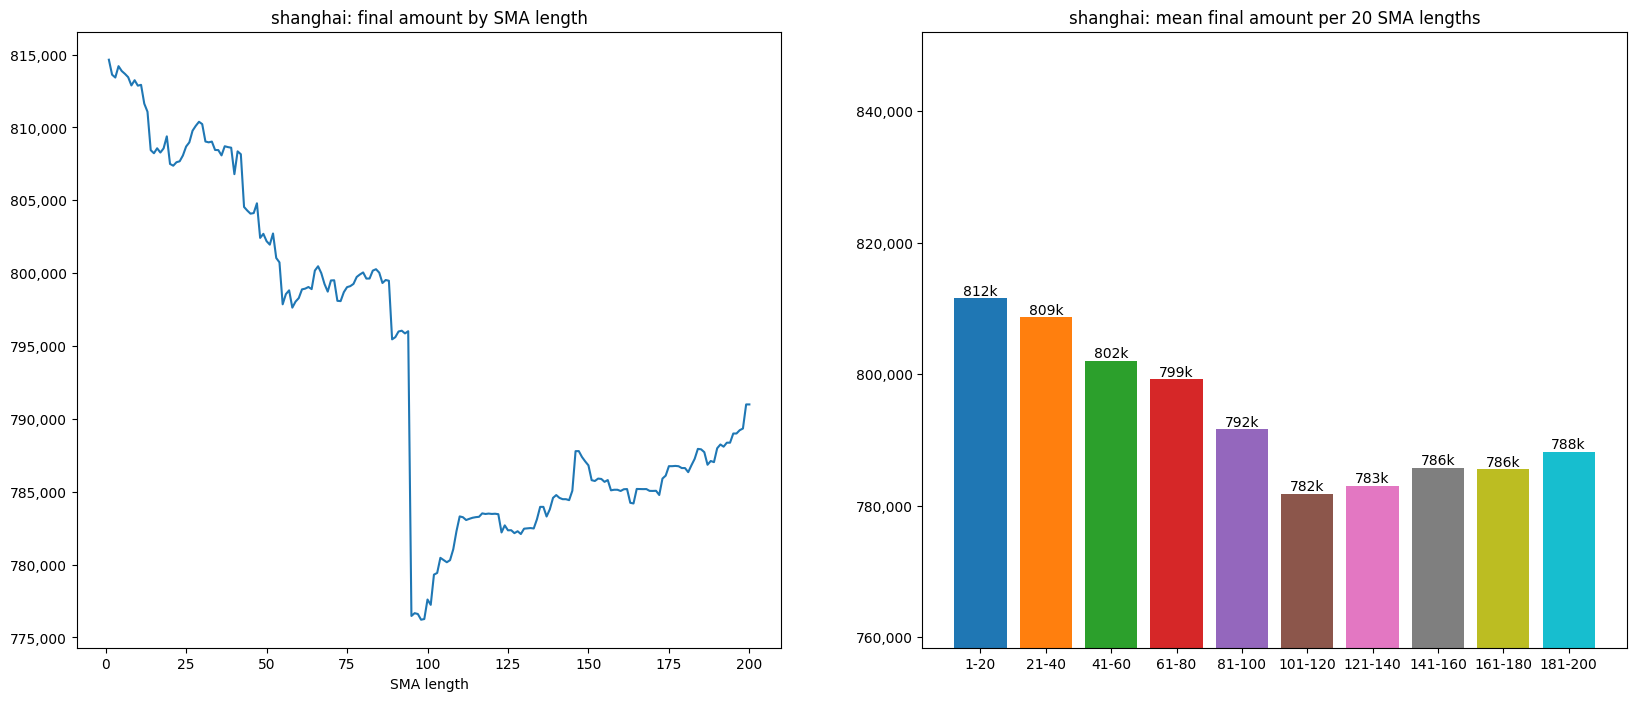

In [2]:
import pandas as pd
from pathlib import Path
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

original_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/raw")

processed_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/processed")


original_data_path.mkdir(parents=True, exist_ok=True) # exists is if does not exist create else ignore parents is the same for folders above it so in this case data

processed_data_path.mkdir(parents=True, exist_ok=True)


SMA_LENGTHS = [50, 100, 200]

indices = {
    "sp500": "^GSPC",
    "nasdaq_comp": "^IXIC",
    "nasdaq100": "^NDX",
    "ftse100": "^FTSE",
    "nikkei": "^N225",
    "dax": "^GDAXI",
    "cac40": "^FCHI",
    "hang_seng": "^HSI",
    "shanghai": "000001.SS",
}

PAYMENT = 1000
INTEREST_RATE = 0.02
START_DATE = "1986-01-01"

DIV_YIELD = {  # placeholders, adjust manually; dax is 0 because it is already total return
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
}

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
          "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]

def sma_calc(df):
    for length in SMA_LENGTHS:
        df[f"sma_{length}"] = df["Close"].rolling(window=length).mean()
    return df

def simulate(df, sma_col, dividend_yield):
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    smas = df[sma_col].tolist()

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available
    start = df.index.get_loc(valid.index[0])

    cash = 0
    units = 0
    next_payment = dates[start].replace(day=1)  # payments on the 1st of each month
    if next_payment < dates[start]:
        next_payment += pd.DateOffset(months=1)

    for i in range(start, len(df)):
        days = (dates[i] - dates[i - 1]).days
        cash *= (1 + INTEREST_RATE) ** (days / 365)
        units *= (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]:
            cash += PAYMENT
            next_payment += pd.DateOffset(months=1)

        if cash > 0 and closes[i - 1] <= smas[i - 1]:
            units += cash / closes[i]
            cash = 0

    return units * closes[-1] + cash  # final amount = everything invested + leftover cash

for name, ticker in indices.items():
    df = yf.download(ticker, start="1950-01-01", progress=False) # progress is a progress bar that shows the download progress

    df.columns = df.columns.get_level_values(0)  # df.columns.get_level_values(0) keeps only the first layer, so the columns become plain names basically nested we want the first layer which is the name of the columns
    df.to_csv(original_data_path / f"{name}_raw.csv")

    gaps = df.index.to_series().diff().dt.days # calculates gap . index is date series turns it to list of values diff subtracts previous row and dt days keeps number of days between the two dates

    print(name, df.index.min().date(), df.index.max().date(), len(df),
          "// duplicates:", df.index.duplicated().sum(),
          "// NaN cells:", df.isna().sum().sum(),
          "// longest gap (in days):", gaps.max())

    df = df.dropna(subset=["Close"])  # drops rows with no price (Yahoo can add an empty last row)
    df = sma_calc(df)

    df.to_csv(processed_data_path / f"{name}_processed.csv")

    final_values = []
    for n in range(1, 201):
        df["sma_n"] = df["Close"].rolling(window=n).mean()
        final_values.append(simulate(df, "sma_n", DIV_YIELD[name]))

    group_names = []
    group_means = []
    group_labels = []
    for first in range(1, 200, 20):
        group = final_values[first - 1:first + 19]
        mean = sum(group) / len(group)
        group_names.append(f"{first}-{first + 19}")
        group_means.append(mean)
        group_labels.append(f"{mean / 1000:,.0f}k")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    ax1.plot(range(1, 201), final_values)
    ax1.set_title(f"{name}: final amount by SMA length")
    ax1.set_xlabel("SMA length")
    ax1.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    bars = ax2.bar(group_names, group_means, color=colors)
    ax2.bar_label(bars, labels=group_labels)
    ax2.set_ylim(bottom=min(group_means) * 0.97)
    ax2.set_title(f"{name}: mean final amount per 20 SMA lengths")
    ax2.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    dca = final_values[0]  # n=1 is DCA
    others = final_values[1:]  # n=2 to 200
    best = max(others)
    worst = min(others)
    beat = 0
    for value in others:
        if value > dca:
            beat += 1

    print(name, "// DCA:", f"{dca:,.0f}",
          "// SMA50:", f"{(final_values[49] / dca - 1) * 100:+.2f}%",
          "// SMA100:", f"{(final_values[99] / dca - 1) * 100:+.2f}%",
          "// SMA200:", f"{(final_values[199] / dca - 1) * 100:+.2f}%",
          "// average n=2-200:", f"{(sum(others) / len(others) / dca - 1) * 100:+.2f}%",
          "// best n:", others.index(best) + 2, f"{(best / dca - 1) * 100:+.2f}%",
          "// worst n:", others.index(worst) + 2, f"{(worst / dca - 1) * 100:+.2f}%",
          "// lengths that beat DCA:", beat, "of 199")

    print("   group means vs DCA:", end=" ")
    for group_name, mean in zip(group_names, group_means):
        print(f"{group_name}: {(mean / dca - 1) * 100:+.2f}%", end=" | ")
    print()

plt.show()
